# Лабораторная работа №4

## Цели и задачи

Применить на практике метод максимального правдоподобия, оценить
статистические свойства получаемых с их помощью статистических оценок параметров
распределений.

In [45]:
import numpy as np

def uniform_pdf(x, params):
    a, b = params
    return 1 / (b - a)

def laplace_pdf(x, params):
    lambd, c = params
    return (lambd / 2) * np.exp(-lambd * np.abs(x - c))
    
def negative_log_likelihood(params, data, pdf):
    return -np.sum([np.log(pdf(x, params)) for x in data])
    
def MLE(data, start_params, pdf, bounds, method, constraints=None):
    if constraints is None:
        constraints = ()
    result = minimize(
        fun=negative_log_likelihood, 
        x0=start_params, 
        args=(data, pdf), 
        method=method, 
        bounds=bounds, 
        constraints=constraints
    )
    return result.x

In [65]:
data = np.random.uniform(low=5, high=10, size=1000)
constraints = [
    {'type': 'ineq', 'fun': lambda params: params[1] - params[0]}
]
a, b = MLE(
    data=data, 
    start_params=(0, 1), 
    pdf=uniform_pdf, 
    bounds=[(None, min(data)), (max(data), None)],
    method='SLSQP',
    constraints=constraints
)
print(f"a = {a}, b = {b}")

a = 5.006866575290117, b = 9.993652179298817


In [66]:
data = np.random.laplace(size=n, loc=2, scale=4)
lambd, c = MLE(
    data=data,
    start_params=(1, 1),
    pdf=laplace_pdf,
    bounds=[(1e-06, None), (None, None)],
    method='L-BFGS-B'
)
print(f"lambda = {lambd}, c = {c}")

lambda = 0.24811814573541105, c = 2.0559644464156057


In [46]:
from scipy.optimize import minimize

n_arr = np.arange(50, 1000, 50)
std_data = {
    "uniform": {
        "a": [],
        "b": []
    },
    "laplace": {
        "lambda": [],
        "c": []
    }
}

for n in n_arr:
    print(n)
    a_arr = []
    b_arr = []
    lambd_arr = []
    c_arr = []
    for _ in range(1000):
        data = np.random.uniform(low=5, high=10, size=n)
        constraints = [
            {'type': 'ineq', 'fun': lambda params: params[1] - params[0]}
        ]
        a, b = MLE(
            data=data, 
            start_params=(0, 1), 
            pdf=uniform_pdf, 
            bounds=[(None, min(data)), (max(data), None)],
            method='SLSQP',
            constraints=constraints
        )
        a_arr.append(a)
        b_arr.append(b)
        data = np.random.laplace(size=n, loc=2, scale=4)
        lambd, c = MLE(
            data=data,
            start_params=(1, 1),
            pdf=laplace_pdf,
            bounds=[(1e-06, None), (None, None)],
            method='L-BFGS-B'
        )
        lambd_arr.append(lambd)
        c_arr.append(c)
    std_data["uniform"]["a"].append(np.std(a_arr))
    std_data["uniform"]["b"].append(np.std(b_arr))
    std_data["laplace"]["lambda"].append(np.std(lambd_arr))
    std_data["laplace"]["c"].append(np.std(c_arr))

50
100
150
200
250
300
350
400
450
500
550


/tmp/ipykernel_200152/1749852114.py:12: RuntimeWarning: divide by zero encountered in log
  return -np.sum([np.log(pdf(x, params)) for x in data])
/home/roman/.config/jupyterlab-desktop/jlab_server/lib/python3.12/site-packages/scipy/optimize/_numdiff.py:592: RuntimeWarning: invalid value encountered in subtract
  df = fun(x1) - f0


600
650
700
750
800
850
900
950


Text(0.5, 1.0, 'Зависимость std оценки параметра b от величины выборки')

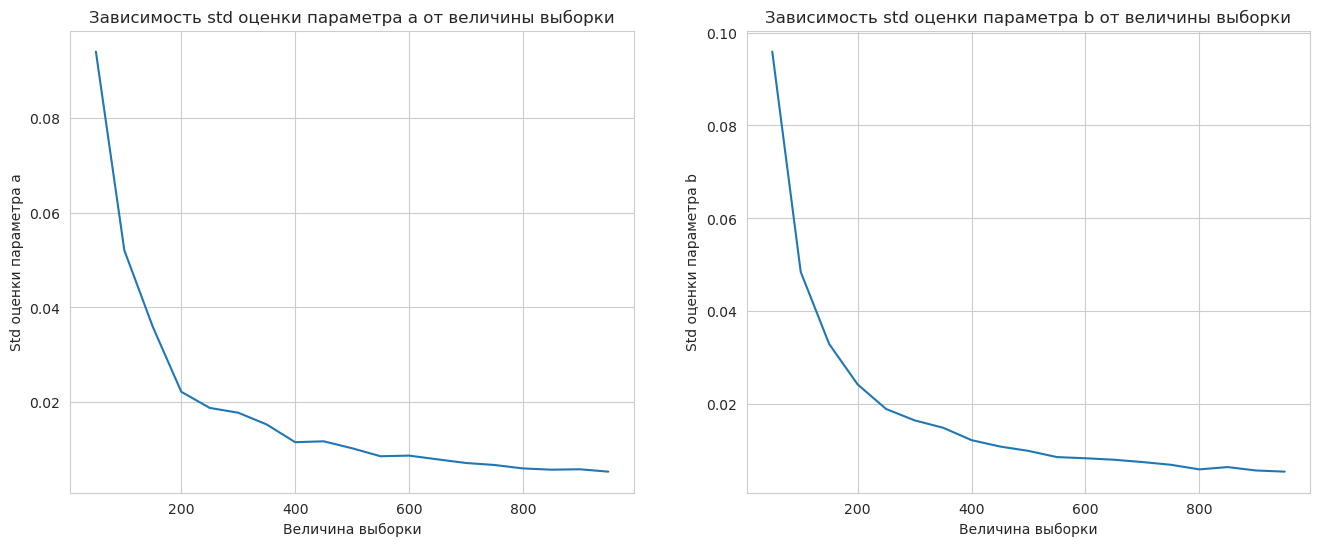

In [63]:
import seaborn as sns
import matplotlib.pyplot as plt


sns.set_style('whitegrid')
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.lineplot(x=n_arr, y=std_data["uniform"]["a"], ax=axes[0])
axes[0].set_xlabel('Величина выборки')
axes[0].set_ylabel('Std оценки параметра a')
axes[0].set_title('Зависимость std оценки параметра a от величины выборки')

sns.lineplot(x=n_arr, y=std_data["uniform"]["b"], ax=axes[1])
axes[1].set_xlabel('Величина выборки')
axes[1].set_ylabel('Std оценки параметра b')
axes[1].set_title('Зависимость std оценки параметра b от величины выборки')

Text(0.5, 1.0, 'Зависимость std оценки параметра c от величины выборки')

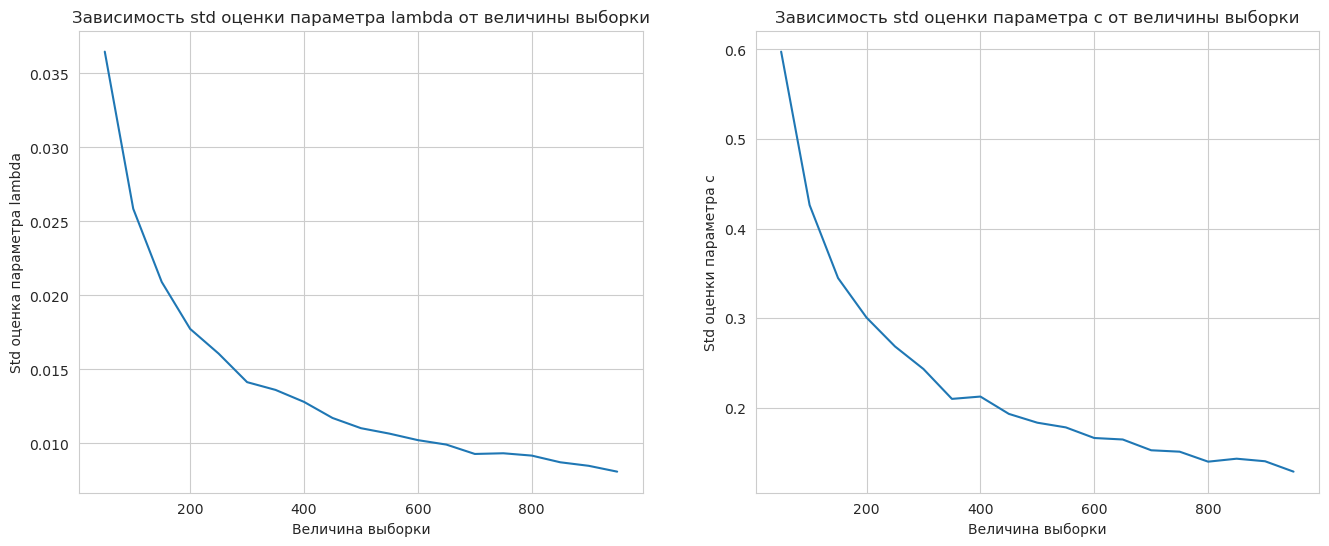

In [64]:
import seaborn as sns
import matplotlib.pyplot as plt


fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.lineplot(x=n_arr, y=std_data["laplace"]["lambda"], ax=axes[0])
axes[0].set_xlabel('Величина выборки')
axes[0].set_ylabel('Std оценка параметра lambda')
axes[0].set_title('Зависимость std оценки параметра lambda от величины выборки')

sns.lineplot(x=n_arr, y=std_data["laplace"]["c"], ax=axes[1])
axes[1].set_xlabel('Величина выборки')
axes[1].set_ylabel('Std оценки параметра c')
axes[1].set_title('Зависимость std оценки параметра c от величины выборки')

## Выводы

1. С помощью метода максимального правдоподобия оценены параметры равномерного распределения и распределения Лапласа.
2. Построены графики зависимости СКО оценок параметров равномерного распределения и распределения Лапласа от величины выборки. Из полученных данных следует, что с ростом величины выборки СКО оценок стремится к 0.